**Import**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, auc, confusion_matrix

**Caricamento dataset**

In [ ]:
df_train = pd.read_csv('dataset_training.csv')
df_real = pd.read_csv('dataset_finale.csv', sep=';', decimal=',')
df_real = df_real.rename(columns={'sar': 'surfaceare'})

**Pulizia e bilanciamento delle classi**

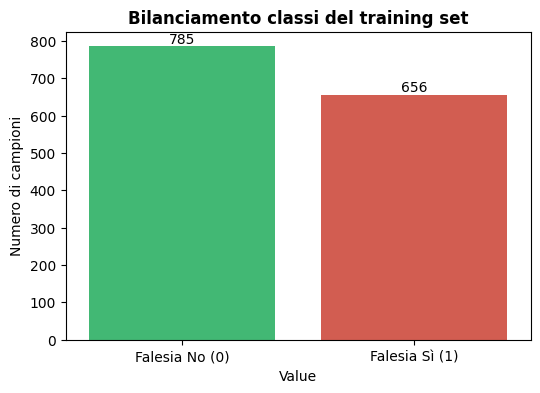

In [ ]:
df_train = df_train.dropna()
df_real = df_real.dropna()

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_train, x='Value', hue='Value', palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title('Bilanciamento classi del training set', fontweight='bold')
plt.xticks(ticks=[0, 1], labels=['Falesia No (0)', 'Falesia Sì (1)'])
plt.ylabel('Numero di campioni')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

**Rimozione valori che non sono caratteristiche**

In [ ]:
df_train = df_train.drop(['FID', 'ID'], axis=1)
df_train.head()

,DTM_elevat,roughness,slope,dissection,surfaceare,distance,litologia,Value
0,13.136,19.370,28.367,0.382,113.646,9.434,5,1.0
1,12.500,14.896,25.074,0.327,110.404,7.280,4,1.0
2,20.551,47.818,45.005,0.329,154.865,12.000,5,1.0
3,14.460,22.304,40.981,0.228,132.464,2.828,4,1.0
4,6.921,13.660,24.431,0.187,109.835,1.000,4,1.0


**Plot comparativo delle caratteristiche**

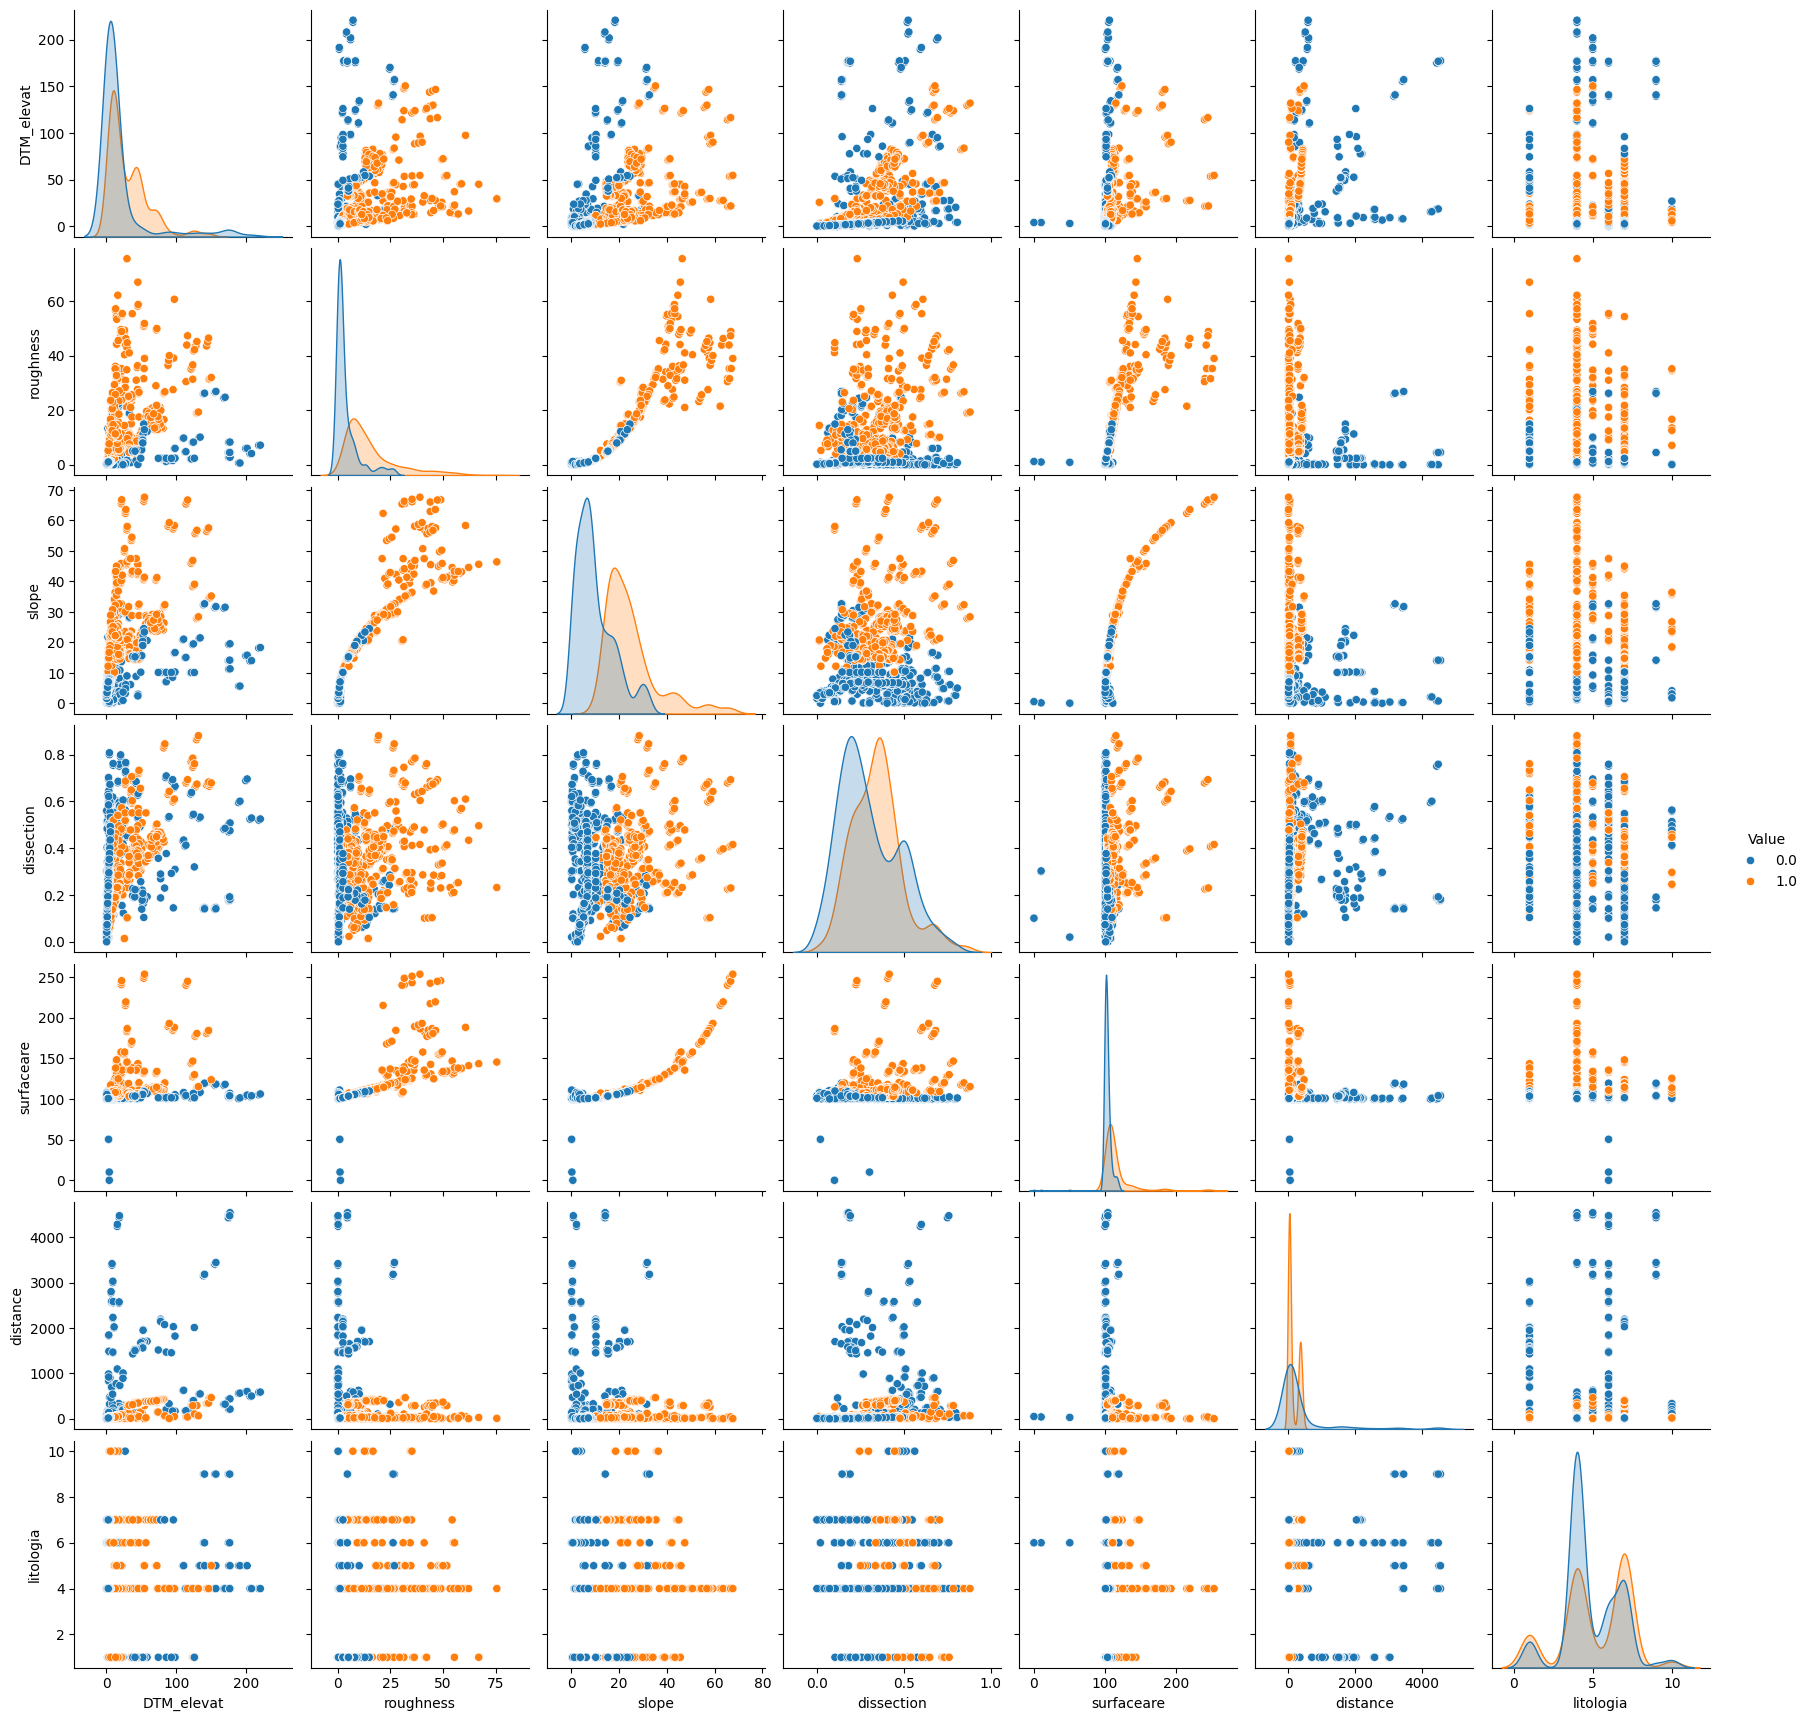

In [ ]:
sns.pairplot(df_train, hue='Value')

**Separazione feature/target e salvataggio coordinate per QGIS**

In [ ]:
X = df_train.drop(columns=['Value'])
y = df_train['Value'].copy()

print("Dimensioni training:", X.shape, y.shape)

X_coord = df_real['x']
Y_coord = df_real['y']
ID_coord = df_real['id']

df_real_features = df_real[X.columns]

Dimensioni training: (1441, 7) (1441,)


**Divisione del dataset**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    train_size=0.8,
                                                    shuffle=True,
                                                    stratify=y,
                                                    random_state=42)

print(f"Campioni di training: {X_train.shape[0]}")
print(f"Campioni di test: {X_test.shape[0]}")

Campioni di training: 1152
Campioni di test: 289


**Normalizzazione di input**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

df_real_features_scaled = scaler.transform(df_real_features)

**Random Forest**

In [ ]:
rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(X_train, y_train) #non scalati

RandomForestClassifier(class_weight='balanced', random_state=42)

**SVM**

In [ ]:
svm = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm.fit(X_train_scaled, y_train)

SVC(class_weight='balanced', probability=True, random_state=42)

**Valutazione, confronto e grafici**

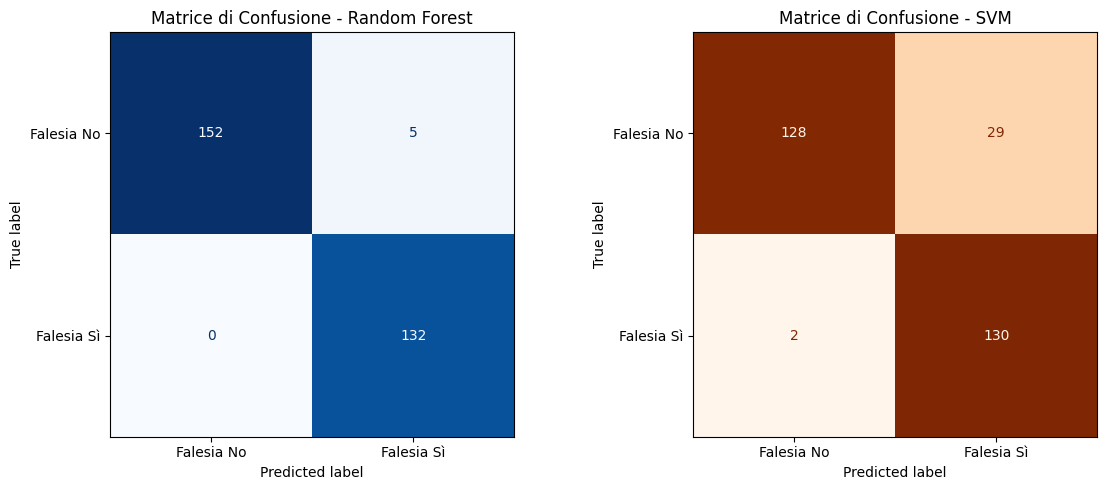

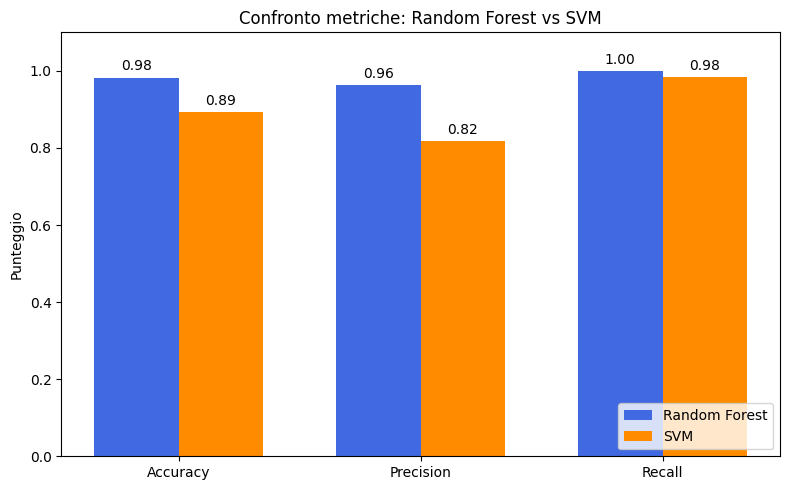

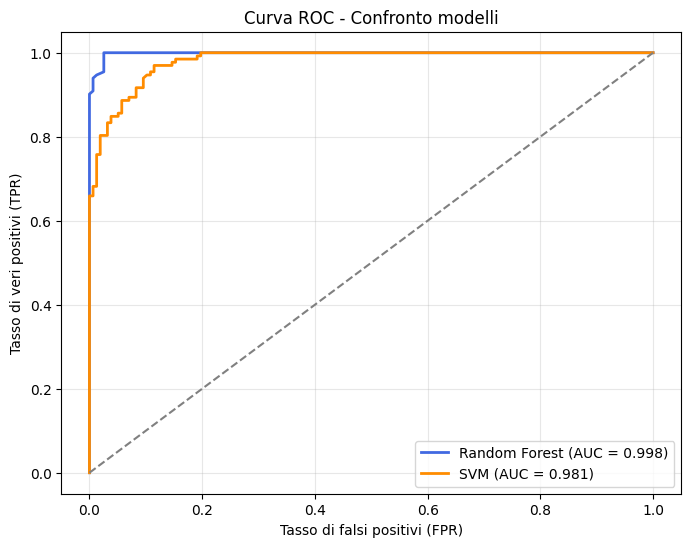

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_pred_rf = rf.predict(X_test)
acc_rf, prec_rf, rec_rf = accuracy_score(y_test, y_pred_rf), precision_score(y_test, y_pred_rf), recall_score(y_test, y_pred_rf)

y_pred_svm = svm.predict(X_test_scaled)
acc_svm, prec_svm, rec_svm = accuracy_score(y_test, y_pred_svm), precision_score(y_test, y_pred_svm), recall_score(y_test, y_pred_svm)

#MATRICI DI CONFUSIONE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
etichette_classi = ['Falesia No', 'Falesia Sì']

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, ax=axes[0], cmap='Blues', colorbar=False, display_labels=etichette_classi)
axes[0].set_title('Matrice di Confusione - Random Forest')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm, ax=axes[1], cmap='Oranges', colorbar=False, display_labels=etichette_classi)
axes[1].set_title('Matrice di Confusione - SVM')

plt.tight_layout()
plt.show()

#RANDOM FOREST VS. SVM
labels = ['Accuracy', 'Precision', 'Recall']
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, [acc_rf, prec_rf, rec_rf], width, label='Random Forest', color='royalblue')
rects2 = ax.bar(x + width/2, [acc_svm, prec_svm, rec_svm], width, label='SVM', color='darkorange')

ax.set_ylabel('Punteggio')
ax.set_title('Confronto metriche: Random Forest vs SVM')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)
ax.legend(loc='lower right')
ax.bar_label(rects1, fmt='%.2f', padding=3)
ax.bar_label(rects2, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

#CURVA ROC
y_prob_rf = rf.predict_proba(X_test)[:, 1]
y_prob_svm = svm.predict_proba(X_test_scaled)[:, 1]

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='royalblue', lw=2, label=f'Random Forest (AUC = {auc(fpr_rf, tpr_rf):.3f})')
plt.plot(fpr_svm, tpr_svm, color='darkorange', lw=2, label=f'SVM (AUC = {auc(fpr_svm, tpr_svm):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlabel('Tasso di falsi positivi (FPR)')
plt.ylabel('Tasso di veri positivi (TPR)')
plt.title('Curva ROC - Confronto modelli')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

**Predizioni finali per QGIS**

In [ ]:
predizioni_prob_rf = rf.predict_proba(df_real_features)[:, 1]
predizioni_prob_svm = svm.predict_proba(df_real_features_scaled)[:, 1]


df_rf = pd.DataFrame()
df_rf['id'] = ID_coord
df_rf['X'] = X_coord
df_rf['Y'] = Y_coord
df_rf['Probabilita_RF'] = predizioni_prob_rf

file_output_rf = 'mappa_predizioni_RF.csv'
df_rf.to_csv(file_output_rf, index=False)


df_svm = pd.DataFrame()
df_svm['id'] = ID_coord
df_svm['X'] = X_coord
df_svm['Y'] = Y_coord
df_svm['Probabilita_SVM'] = predizioni_prob_svm

file_output_svm = 'mappa_predizioni_SVM.csv'
df_svm.to_csv(file_output_svm, index=False)


print(f"1. {file_output_rf}")
print(f"2. {file_output_svm}")

1. mappa_predizioni_RF.csv
2. mappa_predizioni_SVM.csv
